<a href="https://colab.research.google.com/github/Thejake22/EN3160-Assignment-2-on-Fitting-and-Alignment/blob/main/EN3160_Assignment_2_on_Fitting_and_Alignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **EN3160 Assignment 2 on Fitting and Alignment**

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving flag.png to flag.png
Saving the_berry_farms_sunflower_field.jpeg to the_berry_farms_sunflower_field.jpeg
Saving wadham.jpg to wadham.jpg


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize
import os
import sys

1. In this question, using the knowledge on blob detection, i.e., using Laplacian of Gaussians and scale-space
extrema detection, we will detect and draw circles in the sunflower field image. Use the sunflower field
image provided:

sigma range used: 4.00 .. 60.00 (25 scales)
Largest circles (x, y, radius, sigma):
  centre=(242, 0)  r=54.0  sigma=38.21
  centre=(108, 144)  r=43.1  sigma=30.49
  centre=(1, 142)  r=34.4  sigma=24.33
  centre=(28, 65)  r=21.9  sigma=15.49
  centre=(269, 149)  r=17.5  sigma=12.36
  centre=(203, 152)  r=17.5  sigma=12.36
  centre=(124, 359)  r=17.5  sigma=12.36
  centre=(284, 359)  r=12.5  sigma=8.81
  centre=(121, 48)  r=12.5  sigma=8.81
  centre=(170, 275)  r=9.9  sigma=7.03


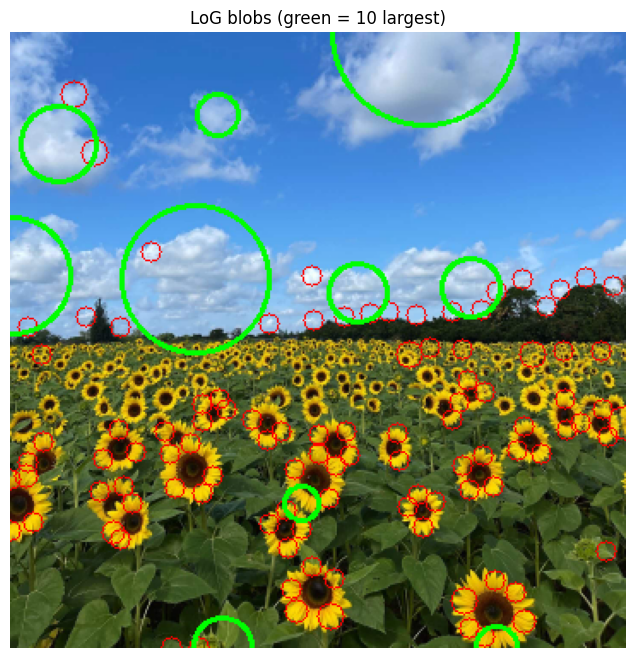

In [ ]:
"""Q1 - Blob (sunflower) detection with scale-normalised Laplacian of Gaussian
and 3-D (x, y, sigma) scale-space extrema. No cv2.HoughCircles."""


# ---------------- parameters ----------------
SIGMA_MIN, SIGMA_MAX, N_SCALES = 4.0, 60.0, 25   # range of sigma used (report this!)
REL_THRESH = 0.4      # keep extrema above this fraction of the global max response
TOP_K = 10             # how many largest circles to draw / report

im = cv.imread('the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, "image not found"
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

# geometric sigma sequence: sigma_i = SIGMA_MIN * k^i
sigmas = np.geomspace(SIGMA_MIN, SIGMA_MAX, N_SCALES)

# ---------------- scale space ----------------
# Sunflower heads are BRIGHT blobs -> LoG is negative at the centre, so use -LoG.
# Multiply by sigma^2 (scale normalisation) so responses are comparable across scales.
stack = []
for s in sigmas:
    g = cv.GaussianBlur(gray, (0, 0), s)
    log = cv.Laplacian(g, cv.CV_32F)
    stack.append(-(s ** 2) * log)
stack = np.stack(stack)                      # shape (S, H, W)

# ---------------- extrema detection ----------------
# a point is an extremum if it is the max in its (scale, y, x) neighbourhood
local_max = maximum_filter(stack, size=(3, 5, 5))
mask = (stack == local_max) & (stack > REL_THRESH * stack.max())
si, ys, xs = np.nonzero(mask)
blobs = [(x, y, np.sqrt(2) * sigmas[i], stack[i, y, x]) for i, y, x in zip(si, ys, xs)]
# blob radius r = sqrt(2) * sigma

# ---------------- simple suppression of overlapping circles ----------------
blobs.sort(key=lambda b: -b[3])              # strongest first
kept = []
for b in blobs:
    if all(np.hypot(b[0] - k[0], b[1] - k[1]) > 0.7 * max(b[2], k[2]) for k in kept):
        kept.append(b)

kept.sort(key=lambda b: -b[2])               # largest radius first
print(f"sigma range used: {sigmas[0]:.2f} .. {sigmas[-1]:.2f} ({N_SCALES} scales)")
print("Largest circles (x, y, radius, sigma):")
for x, y, r, _ in kept[:TOP_K]:
    print(f"  centre=({x}, {y})  r={r:.1f}  sigma={r/np.sqrt(2):.2f}")

# ---------------- draw ----------------
out = im.copy()
for x, y, r, _ in kept:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 0, 255), 1)
for x, y, r, _ in kept[:TOP_K]:               # emphasise the largest ones
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 255, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB))
plt.title(f"LoG blobs (green = {TOP_K} largest)")
plt.axis('off')
plt.savefig('q1_result.png', dpi=150, bbox_inches='tight')
plt.show()

A blob of radius r responds most strongly to a Laplacian of Gaussian with σ = r/√2. We compute the *scale-normalised* LoG, σ²·∇²G_σ * I, at many σ. We then look for points that are local extrema in (x, y, σ). Each extremum gives  a circle with centre (x, y) and radius r = √2·σ.

A larger σ range means more computation but more sunflower sizes found. A lower threshold gives more detections but more false positives from background. Perspective makes distant flowers small, which is why a range of scales is needed. `REL_THRESH` and the neighbourhood size are the main tuning knobs.

**Question 2**

RANSAC line: a=0.713 b=0.701 d=1.467   (|n|=1.000), 59 inliers
RANSAC circle: centre=(1.89,2.96) r=10.08, 41 inliers (truth: (2,3), r=10)


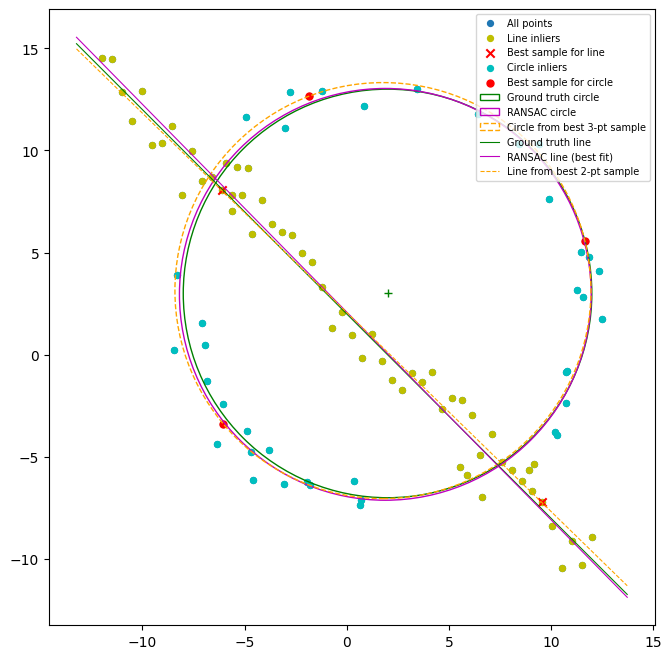

Circle-first (no radius guard): r=10.2, inliers=55


In [ ]:
"""Q2 - RANSAC line fit (total least squares, ||[a,b]||=1), then RANSAC circle fit on the remaining points, refined with scipy.optimize.minimize."""
rng = np.random.default_rng(0)

# data generation
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = rng.uniform(0, 2 * np.pi, half_n)
n = s * rng.standard_normal(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.column_stack((x, y))
s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * rng.standard_normal(half_n)
X_line = np.column_stack((x, y))
X = np.vstack((X_circ, X_line))


# line model
def line_from_two_points(p, q):
    """Unit normal (a,b) and distance d such that a*x + b*y = d."""
    dx, dy = q - p
    norm = np.hypot(dx, dy)
    if norm < 1e-9:
        return None
    a, b_ = -dy / norm, dx / norm          # unit normal => constraint ||[a,b]|| = 1
    return a, b_, a * p[0] + b_ * p[1]


def line_error(model, P):
    a, b_, d = model
    return np.abs(P @ np.array([a, b_]) - d)    # normal (perpendicular) distance


def fit_line_tls(P):
    """Total least squares on inliers: normal = eigenvector of smallest eigenvalue."""
    mu = P.mean(axis=0)
    _, _, Vt = np.linalg.svd(P - mu)
    a, b_ = Vt[-1]
    return a, b_, a * mu[0] + b_ * mu[1]


def ransac_line(P, thresh, min_inliers, iters=300):
    best = None
    for _ in range(iters):
        i, j = rng.choice(len(P), 2, replace=False)
        mdl = line_from_two_points(P[i], P[j])
        if mdl is None:
            continue
        inl = line_error(mdl, P) < thresh
        if inl.sum() >= min_inliers and (best is None or inl.sum() > best['inl'].sum()):
            best = dict(model=mdl, inl=inl, sample=P[[i, j]])
    return best


# circle model
def circle_from_three_points(p1, p2, p3):
    A = 2 * np.array([[p2[0] - p1[0], p2[1] - p1[1]],
                      [p3[0] - p1[0], p3[1] - p1[1]]])
    if abs(np.linalg.det(A)) < 1e-6:        # collinear -> no circle
        return None
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    cx, cy = np.linalg.solve(A, rhs)
    return cx, cy, np.hypot(p1[0] - cx, p1[1] - cy)


def circle_error(model, P):
    cx, cy, rad = model
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rad)   # radial error


def fit_circle_opt(P, init):
    cost = lambda th: np.sum(circle_error(th, P) ** 2)
    return minimize(cost, init, method='Nelder-Mead').x


def ransac_circle(P, thresh, min_inliers, iters=500, max_radius=50):
    best = None
    for _ in range(iters):
        idx = rng.choice(len(P), 3, replace=False)
        mdl = circle_from_three_points(*P[idx])
        if mdl is None or mdl[2] > max_radius:   # reject degenerate near-line circles
            continue
        inl = circle_error(mdl, P) < thresh
        if inl.sum() >= min_inliers and (best is None or inl.sum() > best['inl'].sum()):
            best = dict(model=mdl, inl=inl, sample=P[idx])
    return best


# (a) line
# line noise sigma = 1  -> 2*sigma gives ~95% of true inliers
LINE_T, LINE_MIN = 2.0, 35
best_line = ransac_line(X, LINE_T, LINE_MIN)
line_inl = best_line['inl']
a, b_, d = fit_line_tls(X[line_inl])
print(f"RANSAC line: a={a:.3f} b={b_:.3f} d={d:.3f}   (|n|={np.hypot(a, b_):.3f}), "
      f"{line_inl.sum()} inliers")

# (b) circle on the remnant
rem = X[~line_inl]
# radial noise sigma = r/16 = 0.625, threshold ~2*sigma
CIRC_T, CIRC_MIN = 1.25, 25
best_circ = ransac_circle(rem, CIRC_T, CIRC_MIN)
circ_inl = best_circ['inl']
cx, cy, rad = fit_circle_opt(rem[circ_inl], best_circ['model'])
print(f"RANSAC circle: centre=({cx:.2f},{cy:.2f}) r={rad:.2f}, {circ_inl.sum()} inliers "
      f"(truth: ({x0_gt},{y0_gt}), r={r})")

# (c) plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X[:, 0], X[:, 1], s=18, label='All points')
ax.scatter(*X[line_inl].T, s=18, c='y', label='Line inliers')
ax.scatter(*best_line['sample'].T, c='r', marker='x', label='Best sample for line')
ax.scatter(*rem[circ_inl].T, s=18, c='c', label='Circle inliers')
ax.scatter(*best_circ['sample'].T, c='r', s=25, label='Best sample for circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', c='g')
ax.add_patch(plt.Circle((cx, cy), rad, color='m', fill=False, label='RANSAC circle'))
ax.add_patch(plt.Circle(best_circ['model'][:2], best_circ['model'][2], color='orange',
                        fill=False, ls='--', label='Circle from best 3-pt sample'))
xs = np.array(ax.get_xlim())
ax.plot(xs, m * xs + b, c='g', lw=0.8, label='Ground truth line')
ax.plot(xs, (d - a * xs) / b_, c='m', lw=0.8, label='RANSAC line (best fit)')
a0, b0, d0 = best_line['model']
ax.plot(xs, (d0 - a0 * xs) / b0, c='orange', ls='--', lw=0.8, label='Line from best 2-pt sample')
ax.set_aspect('equal'); ax.legend(fontsize=7, loc='upper right')
plt.savefig('q2_result.png', dpi=150, bbox_inches='tight')
if matplotlib.get_backend().lower() != 'agg':
    plt.show()

# ---------------- (d) circle first? ----------------
best_c_first = ransac_circle(X, CIRC_T, CIRC_MIN, max_radius=1e9)   # no radius guard
print("Circle-first (no radius guard): r=%.1f, inliers=%d" %
      (best_c_first['model'][2], best_c_first['inl'].sum()))

**Line (a).** A line is n·p = d with n = [a, b], ‖n‖ = 1. Two sampled points give the direction (dx, dy). The unit normal is (−dy, dx)/‖(dx, dy)‖, which enforces the constraint, and d = n·p₁. The error is the normal distance |n·p − d|.
- Threshold: the line noise has σ = 1, so I use 2.0 (about 95% of true line points).
- Minimum consensus: 35. Roughly half of the 100 points are on the line, so a good model should have about 50.
- After RANSAC, the final line is re-estimated on all inliers with total least squares. The normal is the singular vector with the smallest singular value, so ‖n‖ = 1 holds exactly.

**Circle (b).** Remove the line inliers, then run RANSAC with 3-point samples. The centre comes from the linear system for the perpendicular bisectors, and r is the distance to one point. The error is the radial error |‖p − c‖ − r|.
- Threshold: the radial noise has σ = r/16 = 0.625, so I use 1.25 (2σ).
- Minimum consensus: 25 of the remaining points.
- Degenerate samples (collinear, or radius > 50) are rejected.
- The best consensus is refined with `scipy.optimize.minimize by minimising the sum of squared radial errors, starting from the RANSAC estimate.

**Test output (seed 0).**
```
RANSAC line: a=0.713 b=0.701 d=1.467 (|n|=1.000), 59 inliers
RANSAC circle: centre=(1.89,2.96) r=10.08, 41 inliers (truth: (2,3), r=10)
```
The true line is x + y = 2, which is n = (0.707, 0.707), d = 1.414. The estimate is very close. The line reports 59 inliers rather than 50 because the line passes through the circle, so some circle points lie within the threshold of the line. This is expected, and it is worth saying in the report.

**(d) What if the circle is fitted first?** The line points make up half the data, so they act as a large set of outliers for the circle model. Two problems follow:
1. A 3-point sample that is nearly collinear gives a huge circle whose boundary approximates the line. That circle can collect many line points as inliers. It can compete with, or beat, the true circle (about 50 points) if the consensus is simply the largest count. So the result depends on the random samples, and a radius limit is needed.
2. The line crosses the circle. Line points near the crossings, plus the circle's own noise, add inliers to wrong models. Even when the true circle wins, its consensus includes some line points, and the refined circle is slightly biased.

In the test run without a radius guard, the true circle did win (r = 10.2, 55 inliers, including some line points). That is luck of the sampling, not a guarantee. Removing the line first is more robust because the line model has only 2 DOF and a simple, well-defined consensus. After removal, the circle only has noise-like outliers, mostly the circle points that were wrongly taken as line inliers.

**Question 3**

base size (h, w): (768, 1024)  flag size (h, w): (960, 1920)


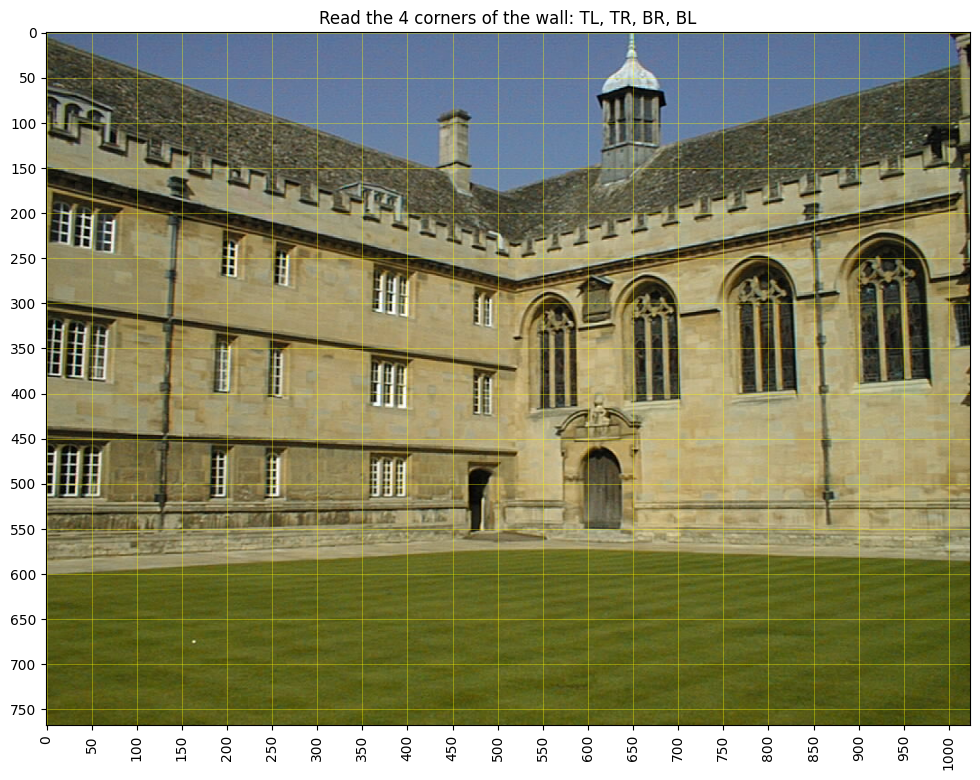

H =
 [[6.25325690e-02 0.00000000e+00 3.50000000e+02]
 [5.21104742e-03 1.45985401e-01 1.50000000e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


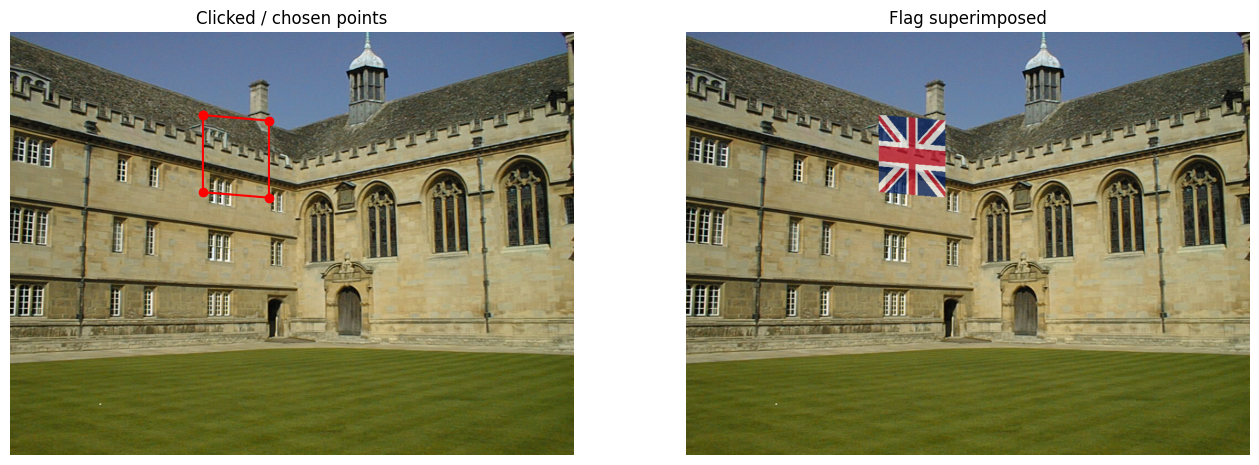

True

In [ ]:
base = cv.imread('wadham.jpg')
over = cv.imread('flag.png')
assert base is not None and over is not None, "check file names / upload location"
print("base size (h, w):", base.shape[:2], " flag size (h, w):", over.shape[:2])

plt.figure(figsize=(12, 9))
plt.imshow(cv.cvtColor(base, cv.COLOR_BGR2RGB))
plt.grid(True, color='yellow', alpha=0.5, lw=0.5)
plt.xticks(np.arange(0, base.shape[1], 50), rotation=90)
plt.yticks(np.arange(0, base.shape[0], 50))
plt.title("Read the 4 corners of the wall: TL, TR, BR, BL")
plt.show()

# points where flag should appear
# (x, y) in the order TL, TR, BR, BL of the planar wall region you want the flag on.
dst = np.float32([[350, 150], [470, 160], [470, 300], [350, 290]])

h, w = over.shape[:2]
src = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])

H, _ = cv.findHomography(src, dst)          # 4 correspondences -> homography
print("H =\n", H)

size = (base.shape[1], base.shape[0])
warped = cv.warpPerspective(over, H, size)
mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, size) > 0

alpha = 0.7
blend = cv.addWeighted(base, 1 - alpha, warped, alpha, 0)
out = base.copy()
out[mask] = blend[mask]

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].imshow(cv.cvtColor(base, cv.COLOR_BGR2RGB))
ax[0].plot(*np.vstack([dst, dst[:1]]).T, 'r-o')
ax[0].set_title("Chosen points")
ax[1].imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB))
ax[1].set_title("Flag superimposed")
for a in ax:
    a.axis('off')
plt.show()
cv.imwrite('wadham_flag.png', out)

A planar surface seen from two views is related by a homography H (3×3, 8 DOF). Four point correspondences determine it.